In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

sns.set_theme(style="whitegrid")

## Step 1: Load and Explore (EDA)
**What I did:** Loaded `loan_data.csv` and inspected its dimensions (`shape`), column data types (`info()`), first 5 records (`head()`), and summary statistics for both numerical and text columns (`describe()`). I then plotted the target distribution (`Loan_Status`) and created 3 exploratory charts: loan approval rate by `Property_Area`, a histogram of `ApplicantIncome`, and a correlation heatmap of numerical features.

**Why:** Before cleaning or modeling, we must understand the size of the dataset, check if the target classes are balanced, spot skewed numerical distributions or outliers, and see which variables correlate with each other.


Dataset Shape: (614, 13)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB
None

--- First 5 Rows ---


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



--- Numerical Summary Statistics ---


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000



--- Categorical Summary Statistics ---


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP002990,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


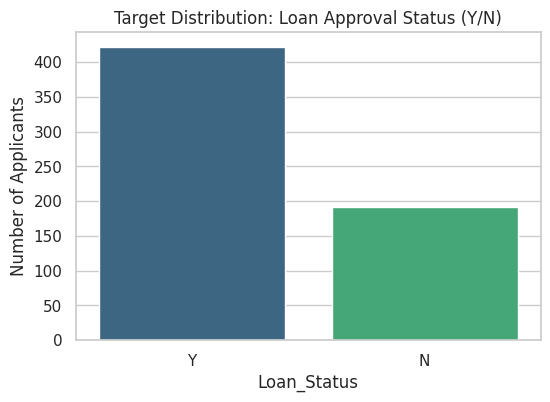

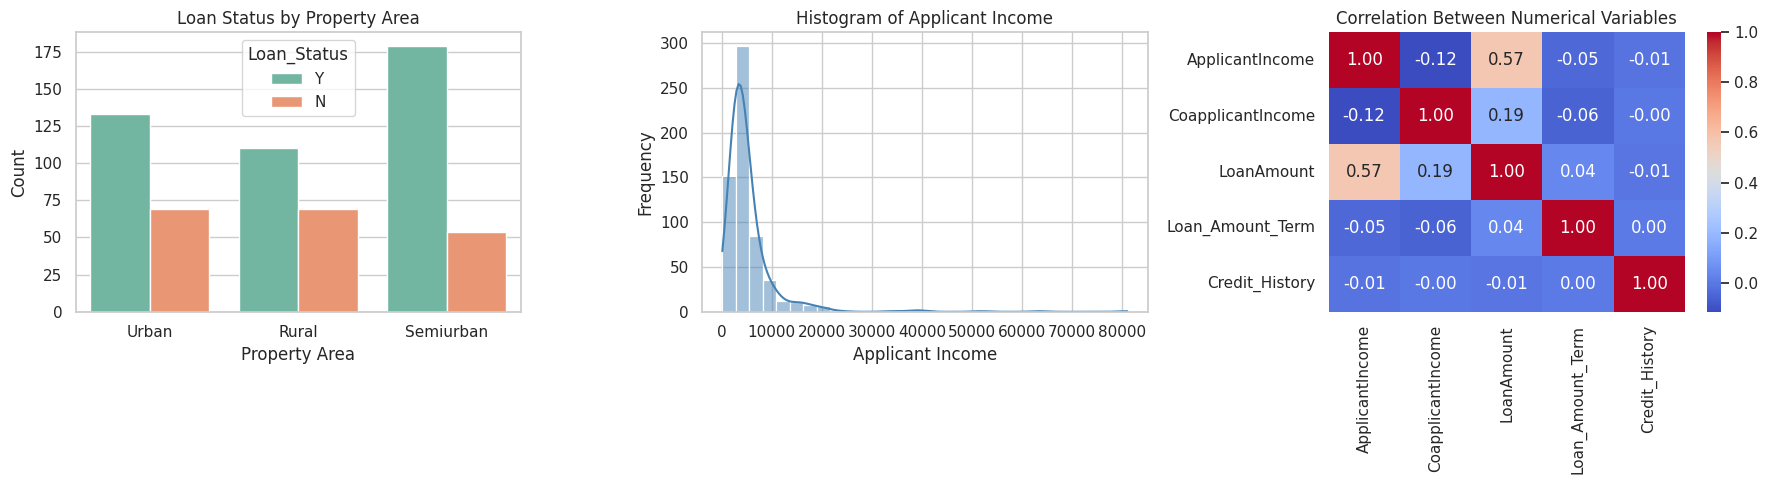

In [4]:
# 1. Load the dataset
df = pd.read_csv("loan_data.csv")

print("Dataset Shape:", df.shape)
print("\n--- Dataset Info ---")
print(df.info())

print("\n--- First 5 Rows ---")
display(df.head())

print("\n--- Numerical Summary Statistics ---")
display(df.describe())

print("\n--- Categorical Summary Statistics ---")
display(df.describe(include="object"))

# 2. Show target distribution (countplot)
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Loan_Status", hue="Loan_Status", palette="viridis", legend=False)
plt.title("Target Distribution: Loan Approval Status (Y/N)")
plt.xlabel("Loan_Status")
plt.ylabel("Number of Applicants")
plt.show()

# 3. Make 3 Exploratory Charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Chart 1: Target by Category (Property_Area vs Loan_Status)
sns.countplot(data=df, x="Property_Area", hue="Loan_Status", palette="Set2", ax=axes[0])
axes[0].set_title("Loan Status by Property Area")
axes[0].set_xlabel("Property Area")
axes[0].set_ylabel("Count")

# Chart 2: Histogram of ApplicantIncome
sns.histplot(df["ApplicantIncome"], bins=30, kde=True, color="steelblue", ax=axes[1])
axes[1].set_title("Histogram of Applicant Income")
axes[1].set_xlabel("Applicant Income")
axes[1].set_ylabel("Frequency")

# Chart 3: Correlation Heatmap of Numerical Variables
numeric_cols_eda = df.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols_eda.corr(), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[2])
axes[2].set_title("Correlation Between Numerical Variables")

plt.tight_layout()
plt.show()

## Step 2: Clean the Data
**What I did:**
1. Checked for duplicate rows and removed any duplicates using `df.drop_duplicates()`.
2. Counted missing values in each column using `df.isnull().sum()` and plotted a bar chart of columns with missing values.
3. Dropped the useless `Loan_ID` column.
4. Decided whether to drop or fill each missing column.

**Why:**
- **Duplicates:** Repeated rows can make a machine learning model look better than it really is during evaluation.
- **Useless Columns:** `Loan_ID` is just a random identifier for each application and carries zero predictive signal.
- **Missing Value Decisions (Drop vs. Fill):** Seven columns have missing values (`Gender`: 13, `Married`: 3, `Dependents`: 15, `Self_Employed`: 32, `LoanAmount`: 22, `Loan_Amount_Term`: 14, `Credit_History`: 50). None of these columns are missing a majority of their data (all are under 8.2% missing), and our dataset has 614 rows. Dropping rows with missing values would throw away 134 useful applicant records (~22% of the dataset). Therefore, I decided to **fill (impute)** all 7 columns in Step 6 using the **training-set median** for numerical columns (`LoanAmount`, `Loan_Amount_Term`, `Credit_History`) because income/loan data is skewed, and the **training-set most frequent value (mode)** for categorical columns (`Gender`, `Married`, `Dependents`, `Self_Employed`).

Duplicate rows before cleaning: 0
Dataset shape after removing duplicates: (614, 13)

Missing values per column:
Gender              13
Married              3
Dependents          15
Self_Employed       32
LoanAmount          22
Loan_Amount_Term    14
Credit_History      50
dtype: int64


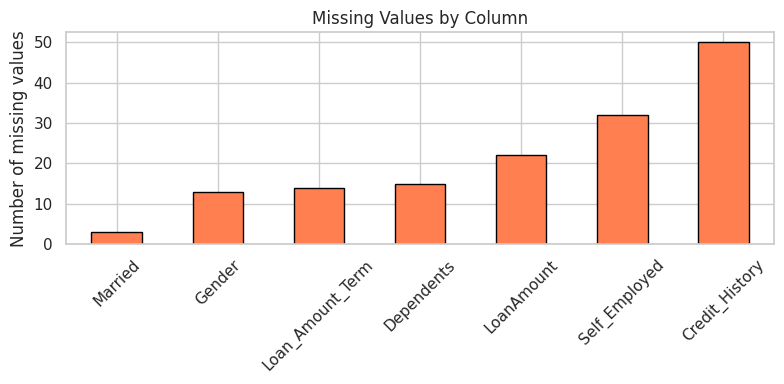


Dropped 'Loan_ID'. Remaining columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status']


In [5]:
# 1. Check for duplicates and remove them
print("Duplicate rows before cleaning:", df.duplicated().sum())
df = df.drop_duplicates()
print("Dataset shape after removing duplicates:", df.shape)

# 2. Count missing values per column and show a bar chart
missing = df.isnull().sum()
print("\nMissing values per column:")
print(missing[missing > 0])

plt.figure(figsize=(8, 4))
missing[missing > 0].sort_values().plot(
    kind="bar",
    color="coral",
    edgecolor="black",
    title="Missing Values by Column"
)
plt.ylabel("Number of missing values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 3. Drop useless columns (Loan_ID)
df = df.drop(columns=["Loan_ID"])
print("\nDropped 'Loan_ID'. Remaining columns:", df.columns.tolist())

## Step 3: Feature Engineering
**What I did:** Created 2 new features from existing columns:
1. `Total_Income` = `ApplicantIncome` + `CoapplicantIncome`
2. `Loan_to_Income_Ratio` = `LoanAmount` / `Total_Income`

**Why each new feature helps the model:**
- **`Total_Income`:** Combines two income signals into total household earning power. An applicant with a modest salary might still easily repay a loan if their co-applicant has a strong income.
- **`Loan_to_Income_Ratio`:** Measures the size of the loan relative to total household income. A loan of 200 is a minor expense for a high-income family but a major default risk for a low-income family.


In [6]:
# Create 2 new features
df["Total_Income"] = df["ApplicantIncome"] + df["CoapplicantIncome"]
df["Loan_to_Income_Ratio"] = df["LoanAmount"] / df["Total_Income"]

print(df[["ApplicantIncome", "CoapplicantIncome", "Total_Income", "LoanAmount", "Loan_to_Income_Ratio"]].head())

   ApplicantIncome  CoapplicantIncome  Total_Income  LoanAmount  \
0             5849                0.0        5849.0         NaN   
1             4583             1508.0        6091.0       128.0   
2             3000                0.0        3000.0        66.0   
3             2583             2358.0        4941.0       120.0   
4             6000                0.0        6000.0       141.0   

   Loan_to_Income_Ratio  
0                   NaN  
1              0.021015  
2              0.022000  
3              0.024287  
4              0.023500  


## Step 4: Select Features and Target
**What I did:** Separated the dataset into input features `X` (all 13 predictor columns) and target `y` (`Loan_Status`), converting `"Y"` to `1` and `"N"` to `0`.

**Why:** Supervised machine learning models require a clear separation between the input variables (`X`) used to make predictions and the numeric target label (`y`) the model is trying to predict.

In [7]:
numeric_features = [
    "ApplicantIncome", "CoapplicantIncome", "LoanAmount",
    "Loan_Amount_Term", "Credit_History", "Total_Income",
    "Loan_to_Income_Ratio"
]

categorical_features = [
    "Gender", "Married", "Dependents",
    "Education", "Self_Employed", "Property_Area"
]

X = df[numeric_features + categorical_features]
y = df["Loan_Status"].map({"Y": 1, "N": 0})

print("Features (X) preview:")
display(X.head())

print("\nTarget (y) preview:")
print(y.head())

Features (X) preview:


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Total_Income,Loan_to_Income_Ratio,Gender,Married,Dependents,Education,Self_Employed,Property_Area
0,5849,0.0,NaN,360.0,1.0,5849.0,NaN,Male,No,0,Graduate,No,Urban
1,4583,1508.0,128.0,360.0,1.0,6091.0,0.021015,Male,Yes,1,Graduate,No,Rural
2,3000,0.0,66.0,360.0,1.0,3000.0,0.022000,Male,Yes,0,Graduate,Yes,Urban
3,2583,2358.0,120.0,360.0,1.0,4941.0,0.024287,Male,Yes,0,Not Graduate,No,Urban
4,6000,0.0,141.0,360.0,1.0,6000.0,0.023500,Male,No,0,Graduate,No,Urban



Target (y) preview:
0    1
1    0
2    1
3    1
4    1
Name: Loan_Status, dtype: int64


## Step 5: Train/Test Split
**What I did:** Split `X` and `y` into 80% training data (`X_train`, `y_train`) and 20% testing data (`X_test`, `y_test`) using `random_state=42` and `stratify=y`.

**Why:**
- Splitting into 80/20 lets the model learn on 80% of the data while holding back 20% as unseen data to test real-world performance.
- `stratify=y` ensures both the training and testing sets keep the exact same proportion of approved (~68.7%) and rejected (~31.3%) loans.
- `random_state=42` makes the split repeatable every time the notebook is run.

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True))

print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True))

Training rows: 491
Testing rows: 123

Training class proportions:
Loan_Status
1    0.686354
0    0.313646
Name: proportion, dtype: float64

Testing class proportions:
Loan_Status
1    0.691057
0    0.308943
Name: proportion, dtype: float64


## Step 6: Preprocessing (Fit on TRAIN Data Only)
**What I did:** Built a `numeric_pipeline` (`SimpleImputer(strategy="median")` + `StandardScaler()`) and a `categorical_pipeline` (`SimpleImputer(strategy="most_frequent")` + `OneHotEncoder(handle_unknown="ignore", sparse_output=False)`), and combined them using `ColumnTransformer`. I called `fit_transform()` on `X_train` and only `transform()` on `X_test`.

**Why:**
- **Imputation & Encoding:** Models only understand numbers and cannot handle `NaN` values, so missing values are filled and text categories are one-hot encoded into binary (0/1) columns.
- **Scaling:** Features have very different ranges (e.g., `ApplicantIncome` reaches 81,000 while `Credit_History` is 0 to 1). `StandardScaler` puts numerical features on a similar scale so large numbers do not dominate the model.
- **Avoiding Data Leakage:** Fitting the preprocessor on `X_train` only ensures the median, mode, mean, and standard deviation are calculated strictly from the training set. Using `transform()` on `X_test` prevents test data information from leaking into the training process.

In [10]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

# Combine both pipelines with ColumnTransformer
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Fit and transform on TRAIN only; transform only on TEST
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

print("Preprocessing complete!")

Preprocessing complete!


## Step 7: Final Checks
**What I did:** Printed the final shapes of `X_train`, `X_test`, `y_train`, and `y_test`, checked that missing values in both `X_train` and `X_test` equal `0`, and verified the number of samples seen by the fitted preprocessor.

**Why:** Confirming shapes and zero `NaN` values guarantees that the dataset is completely clean, encoded, scaled, and ready for machine learning models in Week 3. Checking `n_samples_seen_` proves that the pipeline was fitted strictly on the 491 training rows and never on the test data.

In [11]:
print("Final X_train shape:", X_train.shape)
print("Final X_test shape: ", X_test.shape)
print("Final y_train shape:", y_train.shape)
print("Final y_test shape: ", y_test.shape)

print("\nMissing values in X_train:", np.isnan(X_train).sum())
print("Missing values in X_test: ", np.isnan(X_test).sum())

# Confirm preprocessor was fitted ONLY on X_train (491 rows)
samples_fitted = preprocessor.named_transformers_["numeric"].named_steps["scaler"].n_samples_seen_
print(f"\nConfirmation: Preprocessor was fitted on {samples_fitted} rows (matches X_train row count of {X_train.shape[0]}). Zero data leakage!")

Final X_train shape: (491, 22)
Final X_test shape:  (123, 22)
Final y_train shape: (491,)
Final y_test shape:  (123,)

Missing values in X_train: 0
Missing values in X_test:  0

Confirmation: Preprocessor was fitted on 491 rows (matches X_train row count of 491). Zero data leakage!
